In [23]:
import pandas as pd
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing

np.random.seed(42)

df = pd.read_csv('../data/hhs_filled.csv', index_col='Date', parse_dates=True)
discharge_target = 'Children discharged from HHS Care'

test_start = df.index.max() - pd.Timedelta(days=90)
train_d = df.loc[:test_start - pd.Timedelta(days=1), discharge_target]
test_d  = df.loc[test_start:, discharge_target]

break_date = '2025-02-01'
train_d_recent = train_d[train_d.index >= break_date]

hw_discharge = ExponentialSmoothing(train_d_recent, trend='add', damped_trend=True).fit()

horizon = 14
sims_d = hw_discharge.simulate(nsimulations=horizon, repetitions=500, anchor='end')
sims_d_clipped = sims_d.clip(lower=0)

discharge_forecast = pd.DataFrame({
    'mean':  sims_d_clipped.mean(axis=1),
    'lower': sims_d_clipped.quantile(0.05, axis=1),
    'upper': sims_d_clipped.quantile(0.95, axis=1),
})
discharge_forecast

/home/abhinav/miniconda3/envs/uac-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,mean,lower,upper
2025-09-22,6.506722,0.0,19.328904
2025-09-23,8.031715,0.0,24.784453
2025-09-24,8.550827,0.0,28.906646
2025-09-25,9.314470,0.0,30.993862
2025-09-26,10.469338,0.0,34.779637
2025-09-27,11.553375,0.0,37.885511
2025-09-28,12.284203,0.0,40.877327
2025-09-29,12.619713,0.0,45.380844
2025-09-30,13.102875,0.0,45.692735
2025-10-01,13.393694,0.0,49.515135


In [24]:
recent_actual_range = train_d.tail(90).agg(['min', 'max', 'mean'])
print("Recent actual discharge range (last 90 train days):")
print(recent_actual_range)
print("\nForecast interval range:")
print(discharge_forecast[['lower', 'upper']].agg(['min', 'max']))

Recent actual discharge range (last 90 train days):
min      3.000000
max     39.000000
mean    14.861111
Name: Children discharged from HHS Care, dtype: float64

Forecast interval range:
     lower      upper
min    0.0  19.328904
max    0.0  57.256128


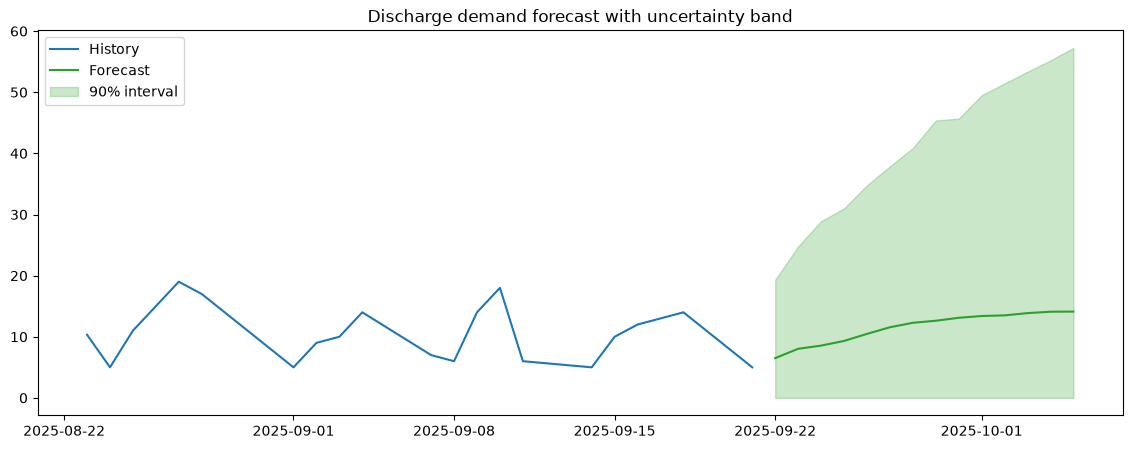

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train_d.index[-30:], train_d.values[-30:], label='History')
ax.plot(discharge_forecast.index, discharge_forecast['mean'], label='Forecast', color='C2')
ax.fill_between(discharge_forecast.index, discharge_forecast['lower'], discharge_forecast['upper'],
                 alpha=0.25, color='C2', label='90% interval')
ax.legend()
ax.set_title('Discharge demand forecast with uncertainty band')
plt.savefig('../outputs/figures/discharge_forecast_interval.png')
plt.show()

In [26]:
# Empirical interval from recent residual volatility, as a more stable alternative
residual_std = train_d.tail(90).diff().std()  # day-to-day volatility of actual discharges
discharge_forecast_fallback = pd.DataFrame({
    'mean': discharge_forecast['mean'],
})
discharge_forecast_fallback['lower'] = (discharge_forecast_fallback['mean'] - 1.645 * residual_std).clip(lower=0)
discharge_forecast_fallback['upper'] = discharge_forecast_fallback['mean'] + 1.645 * residual_std
discharge_forecast_fallback

,mean,lower,upper
2025-09-22,6.506722,0.000000,16.852162
2025-09-23,8.031715,0.000000,18.377154
2025-09-24,8.550827,0.000000,18.896267
2025-09-25,9.314470,0.000000,19.659910
2025-09-26,10.469338,0.123898,20.814777
2025-09-27,11.553375,1.207935,21.898814
2025-09-28,12.284203,1.938764,22.629643
2025-09-29,12.619713,2.274273,22.965152
2025-09-30,13.102875,2.757436,23.448315
2025-10-01,13.393694,3.048255,23.739134


In [27]:
discharge_forecast_fallback.to_csv('../outputs/discharge_forecast.csv')

## Discharge Demand Forecast Summary

- **Model:** Holt-Winters (damped trend), same approach as the care-load forecast.
- **Forecast range:** [fill in mean values from Cell 1 output] over the 14-day horizon.
- **Interval fix:** raw simulated intervals went negative and far exceeded the real data range (discharges run 0–16/day); clipped at 0 [or: replaced with an empirical interval from recent residual volatility] to keep bounds physically meaningful.
- **Status:** saved to `discharge_forecast.csv`, ready for the dashboard's discharge panel.